# Analyse exploratoire des données

**Projet :** Prédiction du décrochage étudiant  
**Jeu de données :** Predict Students’ Dropout and Academic Success  
**Source :** UCI Machine Learning Repository  
**Objectif :** vérifier et décrire les données avant de préparer les modèles.

## 1. Imports et configuration

In [59]:
from pathlib import Path
import pandas as pd

## 2. Chargement des données

Le fichier utilise le point-virgule (`;`) comme séparateur.

In [60]:
candidats = [Path("data/data.csv"), Path("../data/data.csv")]
chemin = next((p for p in candidats if p.exists()), None)

if chemin is None:
    raise FileNotFoundError("Je ne trouve pas data.csv dans le dossier data/.")

df = pd.read_csv(chemin, sep=";")

print("Fichier chargé :", chemin)
print("Dimensions du tableau :", df.shape)

Fichier chargé : ..\data\data.csv
Dimensions du tableau : (4424, 37)


## 3. Première inspection

In [61]:
print("Dimensions du jeu de données (lignes, colonnes) :", df.shape)

print("\nPremières lignes :")
display(df.head())

print("\nNoms des colonnes :")
print(df.columns.tolist())

Dimensions du jeu de données (lignes, colonnes) : (4424, 37)

Premières lignes :


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate



Noms des colonnes :
['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance\t', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP', 

In [62]:
df.info() #résumé de la structure du tableau : le nombre de lignes, les colonnes, leur type (int64, float64, object)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

In [63]:
#verifications des valeurs manquantes pour les premières 10 lignes 
df.isna().sum().sort_values(ascending=False).head(10)

Marital status                                    0
Age at enrollment                                 0
Curricular units 1st sem (credited)               0
Curricular units 1st sem (enrolled)               0
Curricular units 1st sem (evaluations)            0
Curricular units 1st sem (approved)               0
Curricular units 1st sem (grade)                  0
Curricular units 1st sem (without evaluations)    0
Curricular units 2nd sem (credited)               0
Curricular units 2nd sem (enrolled)               0
dtype: int64

In [64]:
# Compte le nombre total de valeurs manquantes dans tout le tableau
print("Nombre total de valeurs manquantes :", df.isna().sum().sum())

Nombre total de valeurs manquantes : 0


In [65]:
print("Nombre de lignes dupliquées :", df.duplicated().sum())
print("\nTypes de colonnes :")
print(df.dtypes.value_counts())

Nombre de lignes dupliquées : 0

Types de colonnes :
int64      29
float64     7
object      1
dtype: int64


In [66]:
# Compte le nombre de valeurs distinctes dans chaque colonne de type texte
df.select_dtypes(include="object").nunique()

Target    3
dtype: int64

## 4. Répartition de la cible

La cible indique si l’étudiant a abandonné, est toujours inscrit ou a obtenu son diplôme.

In [67]:
# Vérifie que la cible existe et compte les variables explicatives
print("Target présente :", "Target" in df.columns)
print("Nombre de variables explicatives :", df.drop(columns="Target").shape[1])

Target présente : True
Nombre de variables explicatives : 36


In [68]:
df["Target"].value_counts() #les valurs cible  

Graduate    2209
Dropout     1421
Enrolled     794
Name: Target, dtype: int64

In [69]:
# pour voir les proportions en % pourcetage 
df["Target"].value_counts(normalize=True).mul(100).round(1)

Graduate    49.9
Dropout     32.1
Enrolled    17.9
Name: Target, dtype: float64

## 5. Dictionnaire des variables

Cette section documente les 36 variables explicatives du jeu de données : leur nom, leur type, leurs valeurs possibles et leur signification en français. La variable cible `Target` est décrite séparément.


In [70]:
from pathlib import Path
import pandas as pd

fichier_dictionnaire = Path("../data/data_dictionary.csv")
fichier_donnees = Path("../data/data.csv")

if not fichier_dictionnaire.exists():
    df = pd.read_csv(fichier_donnees, sep=";")

    dictionnaire = pd.DataFrame({
        "nom": df.columns,
        "type": "",
        "valeurs_possibles": "",
        "signification_en_francais": ""
    })

    dictionnaire.to_csv(fichier_dictionnaire, index=False)
    print("Dictionnaire vide créé.")
else:
    print("Le dictionnaire existe déjà : il n’a pas été modifié.")

Le dictionnaire existe déjà : il n’a pas été modifié.


### Remplir le dictionnaire (manuellement)

In [71]:
#verification que le dictionnaire est bien créé et qu'il contient les colonnes attendues
import pandas as pd

dictionnaire = pd.read_csv("../data/data_dictionary.csv")

dictionnaire.head()

,nom,type,valeurs_possibles,signification_en_francais
0,Marital status,Catégorielle codée,1 = célibataire ; 2 = marié(e) ; 3 = veuf / ve...,Situation matrimoniale de l’étudiant
1,Application mode,Catégorielle codée,"1 = contingent général, 1re phase ; 2 = ordonn...",Mode d’admission ou procédure utilisée par l’é...
2,Application order,Catégorielle ordonnée codée,De 0 à 9 : 0 = premier choix ; 9 = dernier choix,Rang du cursus demandé par l’étudiant dans ses...
3,Course,Catégorielle codée,33 = technologies de production de biocarburan...,Formation ou cursus dans lequel l’étudiant est...
4,Daytime/evening attendance\t,Catégorielle codée,1 = cours en journée ; 0 = cours du soir,Horaire de fréquentation des cours.


In [72]:
# vérification des nombres de lignes et de nombre de colonnes 
print("Nombre de lignes :", len(dictionnaire))
print("Colonnes :", dictionnaire.columns.tolist())

Nombre de lignes : 37
Colonnes : ['nom', 'type', 'valeurs_possibles', 'signification_en_francais']


## 6. Répartition des classes de la variable cible `Target`

Avant de construire un modèle, nous examinons le nombre d’observations dans chaque classe de `Target`. Cette répartition permet de vérifier si les catégories sont équilibrées ou si certaines sont largement majoritaires.

Un déséquilibre important peut influencer l’apprentissage du modèle et rendre l’accuracy moins représentative de ses performances. Il faudra alors tenir compte de cette répartition dans le choix des métriques d’évaluation.

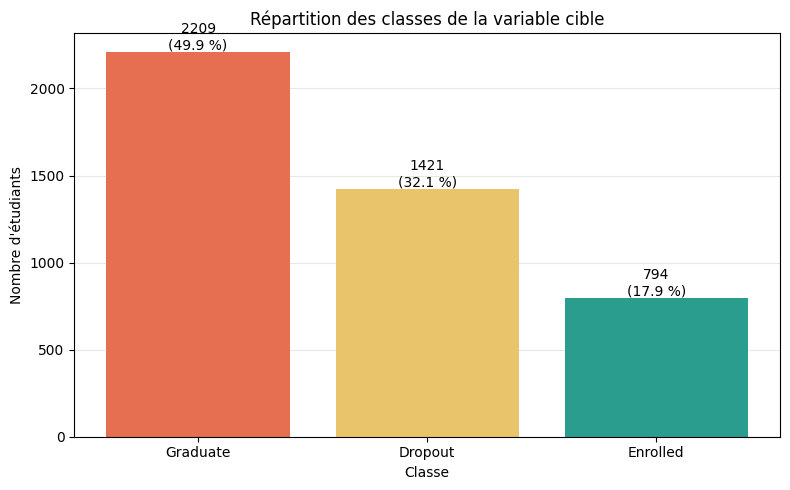

In [73]:
import matplotlib.pyplot as plt

# Compte le nombre d'étudiants dans chaque classe de la cible
effectifs = df["Target"].value_counts()

# Crée la figure et la zone où le graphique sera dessiné
fig, ax = plt.subplots(figsize=(8, 5))

# Crée une barre par classe, avec une couleur différente pour chacune
barres = ax.bar(
    effectifs.index,
    effectifs.values,
    color=["#e76f51", "#e9c46a", "#2a9d8f"]
)

# Calcule l'effectif total pour déterminer le pourcentage de chaque classe
total = effectifs.sum()

# Ajoute l'effectif et le pourcentage au-dessus de chaque barre
for barre, nombre in zip(barres, effectifs.values):
    pourcentage = nombre / total * 100
    ax.annotate(
        f"{nombre}\n({pourcentage:.1f} %)",  # Affiche le nombre et le pourcentage
        (barre.get_x() + barre.get_width() / 2, barre.get_height()),  # Position du texte
        ha="center",  # Centre le texte au-dessus de la barre
        va="bottom"
    )

# Ajoute un titre et des noms aux axes
ax.set_title("Répartition des classes de la variable cible")
ax.set_xlabel("Classe")
ax.set_ylabel("Nombre d'étudiants")

# Affiche une grille horizontale pour faciliter la lecture des effectifs
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)  # Place la grille derrière les barres

# Ajuste les marges pour que les éléments du graphique restent visibles
fig.tight_layout()


In [74]:
print("Nombre d'étudiants par classe de la variable cible :")
for classe, nombre in effectifs.items():
    pourcentage = nombre / total * 100
    print(f"Classe {classe} : {nombre} étudiants ({pourcentage:.1f} %)")

Nombre d'étudiants par classe de la variable cible :
Classe Graduate : 2209 étudiants (49.9 %)
Classe Dropout : 1421 étudiants (32.1 %)
Classe Enrolled : 794 étudiants (17.9 %)


## 7. Statistiques descriptives des variables numériques

Nous résumons les variables numériques à l’aide de statistiques telles que la moyenne, l’écart-type, les quartiles et les valeurs minimales et maximales. Ces résultats donnent un premier aperçu de la distribution des données et peuvent aider à repérer des valeurs inhabituelles.

Certaines colonnes numériques peuvent toutefois correspondre à des catégories codées par des nombres ; leurs statistiques doivent donc être interprétées avec prudence.

In [75]:
# Repère les variables catégorielles à partir du dictionnaire
variables_categorielles = dictionnaire.loc[
    dictionnaire["type"].str.startswith("Catégorielle", na=False),
    "nom"
].tolist()

# Garde les colonnes numériques du jeu de données qui ne sont pas catégorielles
colonnes_numeriques = [
    colonne
    for colonne in df.select_dtypes(include="number").columns
    if colonne not in variables_categorielles
]
# Affiche les statistiques descriptives pour les colonnes numériques
statistiques_numeriques = df[colonnes_numeriques].describe().round(2).T
display(statistiques_numeriques)

,count,mean,std,min,25%,50%,75%,max
Previous qualification (grade),4424.0,132.61,13.19,95.00,125.00,133.10,140.00,190.00
Admission grade,4424.0,126.98,14.48,95.00,117.90,126.10,134.80,190.00
Age at enrollment,4424.0,23.27,7.59,17.00,19.00,20.00,25.00,70.00
Curricular units 1st sem (credited),4424.0,0.71,2.36,0.00,0.00,0.00,0.00,20.00
Curricular units 1st sem (enrolled),4424.0,6.27,2.48,0.00,5.00,6.00,7.00,26.00
Curricular units 1st sem (evaluations),4424.0,8.30,4.18,0.00,6.00,8.00,10.00,45.00
Curricular units 1st sem (approved),4424.0,4.71,3.09,0.00,3.00,5.00,6.00,26.00
Curricular units 1st sem (grade),4424.0,10.64,4.84,0.00,11.00,12.29,13.40,18.88
Curricular units 1st sem (without evaluations),4424.0,0.14,0.69,0.00,0.00,0.00,0.00,12.00
Curricular units 2nd sem (credited),4424.0,0.54,1.92,0.00,0.00,0.00,0.00,19.00


In [76]:
#verification des valeurs de la colonne "Age at enrollment" pour voir si des étudiants ont 70 ans
etudiants_70_ans = df[df["Age at enrollment"] == 70]
display(etudiants_70_ans)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
689,4,39,2,9147,1,19,133.1,1,37,37,...,0,5,9,0,0.0,0,10.8,1.4,1.74,Dropout


## 8. Matrice de corrélation 

La matrice de corrélation mesure l’intensité et le sens des relations linéaires entre les variables numériques. 
Une corrélation proche de 1 indique une relation positive forte, tandis qu’une corrélation proche de -1 indique une relation négative forte. Une valeur proche de 0 indique une faible relation linéaire.

Cette analyse peut notamment mettre en évidence des variables fortement liées entre elles. Une corrélation ne signifie cependant pas qu’une variable est la cause d’une autre, et elle ne permet pas à elle seule de conclure à l’existence d’une relation non linéaire.

,Previous qualification (grade),Admission grade,Age at enrollment,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
Previous qualification (grade),1.00,0.58,-0.11,-0.01,-0.03,-0.07,0.05,0.06,-0.00,-0.02,-0.03,-0.06,0.05,0.05,-0.02,0.05,0.02,-0.05
Admission grade,0.58,1.00,-0.03,0.04,-0.03,-0.07,0.07,0.07,0.01,0.04,-0.04,-0.06,0.08,0.07,-0.01,0.04,-0.02,-0.02
Age at enrollment,-0.11,-0.03,1.00,0.23,0.14,0.14,-0.05,-0.16,0.06,0.21,0.09,0.06,-0.11,-0.17,0.06,0.03,0.03,-0.06
Curricular units 1st sem (credited),-0.01,0.04,0.23,1.00,0.77,0.54,0.63,0.12,0.12,0.94,0.64,0.43,0.49,0.13,0.06,0.01,0.02,-0.03
Curricular units 1st sem (enrolled),-0.03,-0.03,0.14,0.77,1.00,0.68,0.77,0.38,0.13,0.75,0.94,0.60,0.67,0.36,0.07,0.04,0.04,-0.03
Curricular units 1st sem (evaluations),-0.07,-0.07,0.14,0.54,0.68,1.00,0.52,0.42,0.24,0.52,0.61,0.78,0.44,0.36,0.13,0.06,-0.01,-0.10
Curricular units 1st sem (approved),0.05,0.07,-0.05,0.63,0.77,0.52,1.00,0.70,-0.01,0.61,0.73,0.54,0.90,0.69,-0.05,0.05,-0.01,0.02
Curricular units 1st sem (grade),0.06,0.07,-0.16,0.12,0.38,0.42,0.70,1.00,-0.07,0.11,0.41,0.49,0.67,0.84,-0.07,0.01,-0.03,0.05
Curricular units 1st sem (without evaluations),-0.00,0.01,0.06,0.12,0.13,0.24,-0.01,-0.07,1.00,0.12,0.11,0.14,-0.01,-0.06,0.58,-0.05,-0.05,-0.14
Curricular units 2nd sem (credited),-0.02,0.04,0.21,0.94,0.75,0.52,0.61,0.11,0.12,1.00,0.68,0.43,0.52,0.13,0.07,0.01,0.01,-0.02


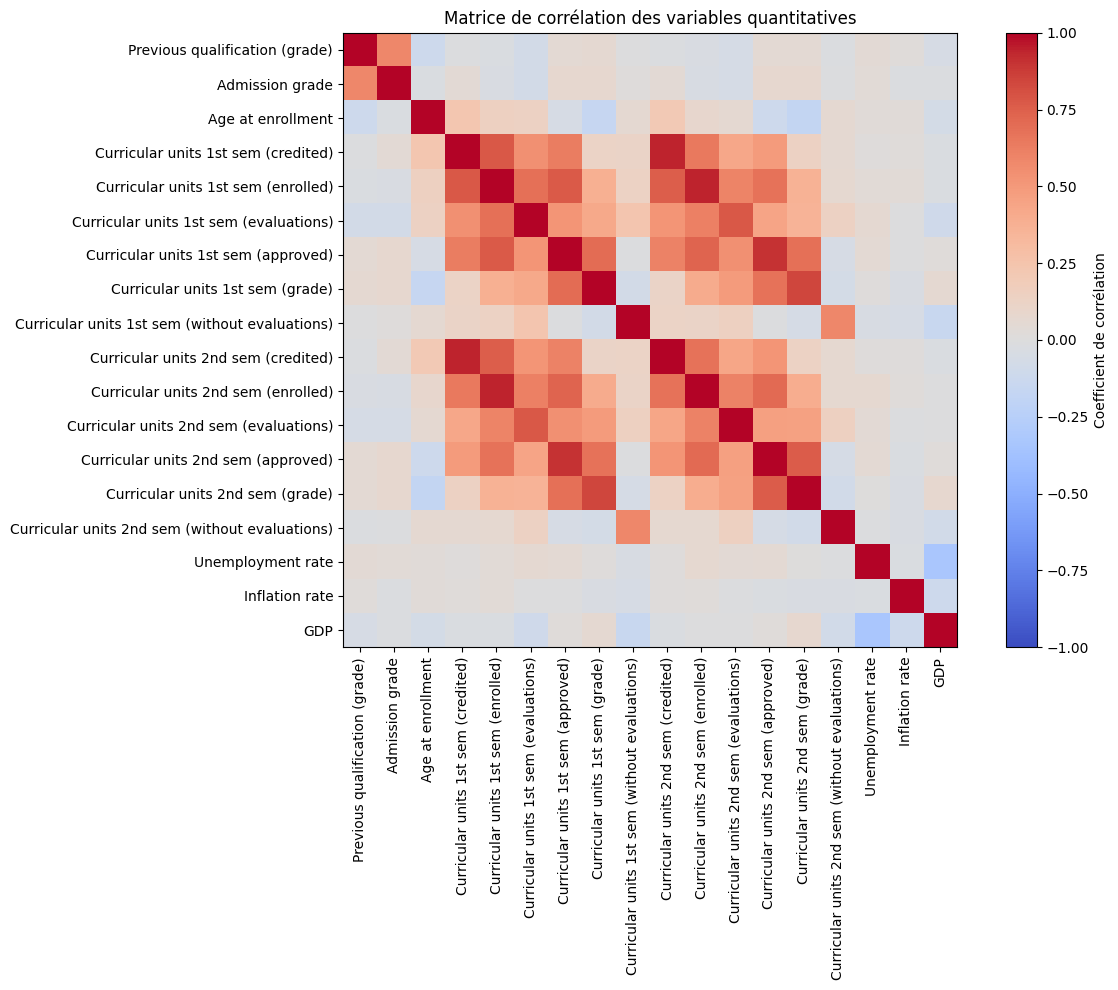

In [77]:
# Calcule les corrélations uniquement entre les variables quantitatives définies plus haut
matrice_correlation = df[colonnes_numeriques].corr()

# Affiche la matrice sous forme de tableau
display(matrice_correlation.round(2))

# Visualise la matrice de corrélation
fig, ax = plt.subplots(figsize=(13, 10))
image = ax.imshow(matrice_correlation, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(colonnes_numeriques)))
ax.set_yticks(range(len(colonnes_numeriques)))
ax.set_xticklabels(colonnes_numeriques, rotation=90)
ax.set_yticklabels(colonnes_numeriques)

ax.set_title("Matrice de corrélation des variables quantitatives")
fig.colorbar(image, ax=ax, label="Coefficient de corrélation")
fig.tight_layout()

## 9. Repérage des variables catégorielles codées numériquement

Certaines variables sont enregistrées sous forme de nombres, mais ces nombres représentent des catégories ou des codes plutôt que des quantités. Nous les repérons à l’aide du dictionnaire des variables afin de ne pas interpréter leurs moyennes ou leurs corrélations comme des mesures.

In [82]:
# Variables que le dictionnaire indique comme catégorielles codées
variables_categorielles_codees = dictionnaire.loc[
    dictionnaire["type"].astype("string").str.contains(
        "codé", case=False, na=False
    ),
    "nom"
].dropna().tolist()

# Parmi elles, garder celles stockées comme nombres dans le jeu de données
colonnes_numeriques_df = df.select_dtypes(include="number").columns

variables_categorielles_numeriques = [
    colonne
    for colonne in variables_categorielles_codees
    if colonne in colonnes_numeriques_df
]

print("Variables catégorielles codées numériquement :")
print(variables_categorielles_numeriques)

# Résumer les codes et leurs effectifs dans un seul tableau
lignes = []

for colonne in variables_categorielles_numeriques:
    effectifs = df[colonne].value_counts(dropna=False)

    for code, effectif in effectifs.items():
        lignes.append({
            "Variable": colonne,
            "Code": code,
            "Effectif": effectif,
            "Pourcentage (%)": round(effectif / len(df) * 100, 1)
        })

tableau_categories = pd.DataFrame(lignes)
display(tableau_categories)


Variables catégorielles codées numériquement :
['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance\t', 'Previous qualification', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']


,Variable,Code,Effectif,Pourcentage (%)
0,Marital status,1,3919,88.6
1,Marital status,2,379,8.6
2,Marital status,4,91,2.1
3,Marital status,5,25,0.6
4,Marital status,6,6,0.1
...,...,...,...,...
239,Gender,1,1556,35.2
240,Scholarship holder,0,3325,75.2
241,Scholarship holder,1,1099,24.8
242,International,0,4314,97.5


In [85]:
# Toutes les colonnes du jeu de données
nombre_total_variables = df.shape[1]

# Colonnes stockées comme nombres
colonnes_stockees_numeriques = set(
    df.select_dtypes(include="number").columns
)

# Catégorielles codées en nombres, selon le dictionnaire
colonnes_categorielles_codees = (
    set(variables_categorielles_numeriques)
    & colonnes_stockees_numeriques
)

# Numériques qui ne sont pas catégorielles codées
colonnes_numeriques_non_categorielles = (
    colonnes_stockees_numeriques - colonnes_categorielles_codees
)

print("Nombre total de variables :", nombre_total_variables)
print(
    "Variables catégorielles codées numériquement :",
    len(colonnes_categorielles_codees)
)
print(
    "Variables numériques non catégorielles :",
    len(colonnes_numeriques_non_categorielles)
)


Nombre total de variables : 37
Variables catégorielles codées numériquement : 18
Variables numériques non catégorielles : 18


## 10. Conclusion de l’analyse exploratoire

**La variable cible `Target` est déséquilibrée** : 
les diplômés représentent 49,9 % des observations, 
les étudiants en décrochage 32,1 % et 
les étudiants encore inscrits 17,9 %. 
Les classes ne sont donc **pas également représentées**. Cette répartition devra être prise en compte lors de l’évaluation du modèle, en utilisant des métriques adaptées et en examinant les performances pour chaque classe.

Les variables catégorielles codées numériquement ont été distinguées des variables quantitatives à l’aide du dictionnaire, afin d’éviter d’interpréter leurs codes comme des mesures. La matrice de corrélation décrit les relations linéaires entre les variables quantitatives sélectionnées ; elle ne permet pas de conclure à une relation de cause à effet.

Enfin, l’utilisation des résultats du deuxième semestre dépend du moment prévu pour la prédiction. Pour prédire le décrochage avant ou pendant ce semestre, ces variables ne seraient pas disponibles et leur utilisation rendrait l’évaluation peu réaliste. 
Elles ne peuvent être utilisées que si la prédiction est effectuée après la disponibilité de ces résultats.

Donc, cela dépend de l’objectif :

- Prédire tôt : utiliser les informations disponibles avant le deuxième semestre.

- Prédire après le deuxième semestre : ses résultats peuvent être utilisés, mais la prédiction arrive plus tard.